In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("C:\\Users\\ABHINAV AR\\data.csv")

df.head()

,CustomerID,Age,AnnualIncome,AvgMonthlyBalance,MonthlyTransactions,CreditScore
0,1001,32,23648,2409,18,611
1,1002,25,24572,14066,13,666
2,1003,33,49234,10935,12,655
3,1004,28,21041,2488,12,607
4,1005,25,36559,11863,10,651


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   CustomerID           100 non-null    int64
 1   Age                  100 non-null    int64
 2   AnnualIncome         100 non-null    int64
 3   AvgMonthlyBalance    100 non-null    int64
 4   MonthlyTransactions  100 non-null    int64
 5   CreditScore          100 non-null    int64
dtypes: int64(6)
memory usage: 4.8 KB


In [4]:
df.shape

(100, 6)

In [5]:
df.describe()

,CustomerID,Age,AnnualIncome,AvgMonthlyBalance,MonthlyTransactions,CreditScore
count,100.000000,100.000000,100.000000,100.000000,100.0000,100.000000
mean,1050.500000,37.330000,94042.210000,84820.950000,56.6400,714.760000
std,29.011492,10.868409,64252.400633,111326.766311,31.3963,66.813039
min,1001.000000,20.000000,21041.000000,2409.000000,10.0000,580.000000
25%,1025.750000,29.750000,43368.250000,10920.500000,28.7500,663.250000
50%,1050.500000,34.500000,75394.000000,29297.000000,56.5000,708.500000
75%,1075.250000,45.000000,115347.500000,97590.000000,77.5000,761.500000
max,1100.000000,65.000000,249146.000000,394088.000000,139.0000,845.000000


In [7]:
df.isnull().sum()
df.duplicated().sum()

0

In [9]:
df = df.drop_duplicates()
X = df.drop("CustomerID", axis=1)

X.head()


,Age,AnnualIncome,AvgMonthlyBalance,MonthlyTransactions,CreditScore
0,32,23648,2409,18,611
1,25,24572,14066,13,666
2,33,49234,10935,12,655
3,28,21041,2488,12,607
4,25,36559,11863,10,651


In [11]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print(X_scaled[:5])

[[-0.49288275 -1.10110817 -0.74400011 -1.23691839 -1.56081395]
 [-1.14019594 -1.08665493 -0.63876283 -1.39697511 -0.73347425]
 [-0.40040944 -0.70089125 -0.66702893 -1.42898646 -0.89894219]
 [-0.862776   -1.14188693 -0.74328691 -1.42898646 -1.62098411]
 [-1.14019594 -0.89915395 -0.65865111 -1.49300915 -0.95911235]]


In [13]:
from sklearn.cluster import KMeans

wcss = []

for i in range(1, 11):

    kmeans = KMeans(n_clusters=i, random_state=42, n_init=10)

    kmeans.fit(X_scaled)

    wcss.append(kmeans.inertia_)

c:\Users\ABHINAV AR\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\ABHINAV AR\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\ABHINAV AR\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\ABHINAV AR\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a m

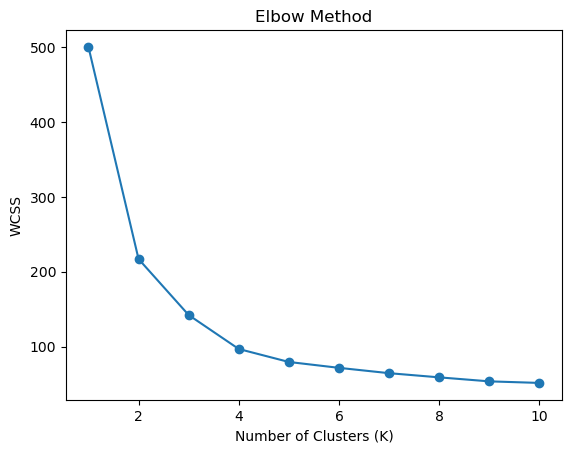

In [14]:
plt.plot(range(1, 11), wcss, marker="o")

plt.title("Elbow Method")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")

plt.show()

In [15]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)

kmeans.fit(X_scaled)

print("K-Means model trained successfully!")

K-Means model trained successfully!


c:\Users\ABHINAV AR\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


In [17]:
df["Cluster"] = kmeans.labels_

print(df[["CustomerID", "Cluster"]].head(10))

print(df["Cluster"].value_counts().sort_index())

   CustomerID  Cluster
0        1001        2
1        1002        2
2        1003        2
3        1004        2
4        1005        2
5        1006        2
6        1007        2
7        1008        2
8        1009        2
9        1010        2
Cluster
0    30
1    25
2    25
3    20
Name: count, dtype: int64


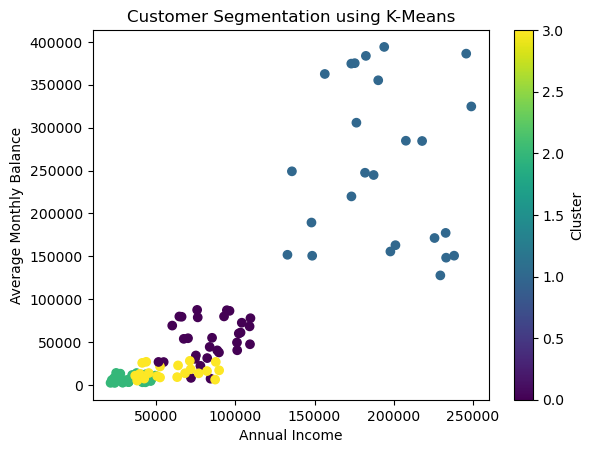

In [18]:
plt.scatter(
    df["AnnualIncome"],
    df["AvgMonthlyBalance"],
    c=df["Cluster"]
)

plt.title("Customer Segmentation using K-Means")
plt.xlabel("Annual Income")
plt.ylabel("Average Monthly Balance")

plt.colorbar(label="Cluster")
plt.show()

In [19]:
print(df.groupby("Cluster").mean(numeric_only=True))

          CustomerID        Age   AnnualIncome  AvgMonthlyBalance  \
Cluster                                                             
0        1045.533333  38.666667   84040.766667       53326.966667   
1        1063.000000  51.040000  193460.920000      255124.080000   
2        1013.000000  28.760000   33762.280000        7522.360000   
3        1089.200000  28.900000   60120.900000       15806.250000   

         MonthlyTransactions  CreditScore  
Cluster                                    
0                      47.80   718.366667  
1                      71.76   805.560000  
2                      18.92   635.600000  
3                      98.15   694.800000  
